# EDA of liciti and illicit address

## 1. Configuration

### 1.1. CONSTANTS and Environment setup

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from varname import nameof
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
ROOT = Path().cwd().resolve().parent
SRC = ROOT.parent / "datasets"
OUTPUT = ROOT.parent / "outputs"
OUTPUT_VARIANTS = {
                    "EDA": OUTPUT / "EDA",
                    "data_cleaning": OUTPUT / "data_cleaning",
                    "data_visualization": OUTPUT / "data_visualization",
                    "hypothesis_testing": OUTPUT / "hypothesis_testing",
                    "threshold_finetuning": OUTPUT / "threshold_finetuning"
                  }
print(f"root directory: {ROOT}")
print(f"src directory: {SRC}")
print(f"output directory: {OUTPUT}")

root directory: /home/annoy/projects/team/capstone-1/dev/data_analysis/src
src directory: /home/annoy/projects/team/capstone-1/dev/data_analysis/datasets
output directory: /home/annoy/projects/team/capstone-1/dev/data_analysis/outputs


In [3]:
OUTPUT.mkdir(parents = True, exist_ok=True)
print(f"{OUTPUT} is created.") if (OUTPUT.exists() and OUTPUT.is_dir()) else print(f"{OUTOUT} is not created")
for directory in OUTPUT_VARIANTS.values():
    (directory).mkdir(parents=True, exist_ok= True)
    if (directory).exists() and (directory).is_dir():
        print(f"{directory} is created.")

/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs is created.
/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/EDA is created.
/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/data_cleaning is created.
/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/data_visualization is created.
/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/hypothesis_testing is created.
/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/threshold_finetuning is created.


### 1.2. Plotting configuration

In [4]:
sns.color_palette("deep")
# Value available: pastel, husl, Set2, Spectral, flare, deep

[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941),
 (0.8549019607843137, 0.5450980392156862, 0.7647058823529411),
 (0.5490196078431373, 0.5490196078431373, 0.5490196078431373),
 (0.8, 0.7254901960784313, 0.4549019607843137),
 (0.39215686274509803, 0.7098039215686275, 0.803921568627451)]

In [5]:
    # 1. Matplotlib Global Configuration (rcParams)
plt.rcParams.update({
    # Figure dimensions and resolution
    "figure.figsize": (8, 5),          # Standard aspect ratio for reports and notebooks
    "figure.dpi": 100,                 # Display resolution
    "savefig.dpi": 300,                # High-resolution export for publication
    "savefig.bbox": "tight",           # Prevent clipping of axis labels and titles
    
    # Typography
    "font.family": "sans-serif",       # Clean, readable default font family
    "font.sans-serif": ["DejaVu Sans", "Helvetica", "Arial"],
    "font.size": 11,                   # Base font size for readability
    "axes.titlesize": 13,              # Subplot title font size
    "axes.labelsize": 11,              # X and Y axis label font size
    "xtick.labelsize": 10,             # Tick label size
    "ytick.labelsize": 10,
    
    # Axes and Grid Styling
    "axes.grid": True,                 # Enable background grid for precise data tracking
    "grid.alpha": 0.3,                 # Subtle grid transparency to avoid overpowering data
    "grid.linestyle": "--",            # Dashed grid lines
    "axes.linewidth": 0.8,             # Spine line width
    "axes.edgecolor": "#333333",       # Dark gray spines instead of harsh pure black
    
    # Lines and Markers
    "lines.linewidth": 1.5,            # Default line thickness for plots
    "patch.linewidth": 0.5,            # Border width for histograms, bars, and KDE fills
    
    # Layout Management
    "figure.autolayout": True          # Automatic tight layout padding adjustment
})
print(f"Loaded Mathplotlib Configuration")

sns.set_theme(style="whitegrid", palette="deep", font="sans-serif")
print(f"Loaded Seaborn Configuration")


Loaded Mathplotlib Configuration
Loaded Seaborn Configuration


### 1.3. Functions

In [6]:
def load_files(src = SRC):
    suspicious_account_data = pd.read_csv(src/"accounts.csv")
    suspicious_transactions_data = pd.read_csv(SRC / 'transactions.csv')
    suspicious_blacklisted_data = pd.read_csv(src/"blacklisted_wallets.csv")
    suspicious_wallet_hops_data = pd.read_csv(src/"wallet_hops.csv")
    return [suspicious_account_data, suspicious_transactions_data, suspicious_blacklisted_data, suspicious_wallet_hops_data]
    
all_dfs = load_files() 
suspicious_account_data, suspicious_transactions_data, suspicious_blacklisted_data, suspicious_wallet_hops_data = all_dfs
all_dfs_name = [nameof(suspicious_account_data),
                nameof(suspicious_wallet_hops_data), 
                nameof(suspicious_transactions_data),
                nameof(suspicious_blacklisted_data)]

In [7]:
from typing import Literal

In [8]:
OUTPUT_VARIANT_VALUES = Literal[[output_directory for output_directory in OUTPUT_VARIANTS.values()]]
OUTPUT_VARIANT_VALUES

typing.Literal[[PosixPath('/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/EDA'), PosixPath('/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/data_cleaning'), PosixPath('/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/data_visualization'), PosixPath('/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/hypothesis_testing'), PosixPath('/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/threshold_finetuning')]]

In [9]:
# === TEXT ===
BOLD_RED_START = '\033[1;31m'
BOLD_END =  '\033[0m'

def bold_text(text:str) -> str:
    return BOLD_RED_START+text+BOLD_END

In [10]:
import time
class efficiency_comparison:
    """If there is time, explore the performance and memory usage of different library data structure."""
    pass

In [11]:
SAVING_EXTENSIONS = [".md", ".png", ".svg"]
def save_img(plot, filename: str, directory: OUTPUT_VARIANT_VALUES, extension: SAVING_EXTENSIONS) -> None:    
    if plot is None:
        raise ValueError(f"Plot has no value. Pass in a value.")
    if directory.strip() not in OUTPUT_VARIANT_VALUES:
        raise ValueError(f"Not a valid output directory. Valid directories: {OUTPUT_VARIANT_VALUES}.")
    if extension.strip() not in SAVING_EXTENSIONS:
        raise ValueError(f"Not a valid extension input. Valid extensions: {SAVING_EXTENSIONS}.")
    filename = filename.strip() + extension
    try: 
        with open(filename, "w") as file:
            file.write(directory)
            print(f"saved {filename} to directory {directory}")
    except Exception as e: 
        raise e

In [12]:
def df_col_unique_val_count(df):
    print(f"=========================Unique val count in {nameof(df)}====================")
    for col in df.columns:
        unique_val_count = df[col].nunique()
        # print(type(unique_val_count))
        if (unique_val_count)<=5:
            print(f"Unique val count in {col}: {bold_text(str(unique_val_count))}")
        else: 
            print(f"Unique val count in {col}: {unique_val_count}")
        if(unique_val_count <=10):
            unique_val = df[col].unique()
            print(f"Unique Values: ")
            print(unique_val)

## 2. PROFILING

#### 2.1. suspicious_account_data

In [13]:
# Read data 
suspicious_account_data.sample(5)

,address,hex_address,first_seen_timestamp,last_seen_timestamp,created_at
74986,TEjfU6vw4ZPLi3qgWUxVVFU3pR97777777,NaN,NaN,NaN,2026-10-28 16:09:29.895406+00
235082,TFfQ81J6Z7mb4YaGvM54iwn672wXiiG6PB,NaN,2025-11-24 19:21:00+00,2025-11-24 19:21:00+00,2026-10-28 18:15:53.268731+00
386580,TEx6gg9vtzvc456JaHVb9aSCeNf9AcHnh2,NaN,NaN,NaN,2026-10-29 04:16:56.395748+00
45966,TH5exvwdmSin8hQSxEfSUFnmzN7FciSbGF,NaN,NaN,NaN,2026-10-28 15:44:32.933484+00
611745,TUFriRMBeZovhLju7mzUNcHpYNMKKypyTg,NaN,2023-01-08 19:08:15+00,2023-01-08 19:08:15+00,2026-10-29 11:11:35.571172+00


In [14]:
suspicious_account_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 664385 entries, 0 to 664384
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   address               664385 non-null  str  
 1   hex_address           8946 non-null    str  
 2   first_seen_timestamp  159062 non-null  str  
 3   last_seen_timestamp   159062 non-null  str  
 4   created_at            664385 non-null  str  
dtypes: str(5)
memory usage: 25.3 MB


In [15]:
suspicious_account_data.describe()

,address,hex_address,first_seen_timestamp,last_seen_timestamp,created_at
count,664385,8946,159062,159062,664385
unique,664385,8946,150915,151439,26717
top,TLhouDRQGCVB6xLuao86ky5Ns8FyoStg4z,0x75bfdc53b18902c3ca06da533687064ed56a37e3,2025-05-30 16:44:39+00,2025-08-19 14:09:09+00,2026-10-28 14:15:20.965029+00
freq,1,1,67,95,8946


In [16]:
df_col_unique_val_count(suspicious_account_data)

=========================Unique val count in df====================
Unique val count in address: 664385
Unique val count in hex_address: 8946
Unique val count in first_seen_timestamp: 150915
Unique val count in last_seen_timestamp: 151439
Unique val count in created_at: 26717


In [17]:
# sample_df = suspicious_account_data.head(50)
# type(sample_df)

In [18]:
# sample_df.to_csv(f"{SRC}/sample_account.csv",index=False)

### 2.2. suspicious_blacklisted_data

In [19]:
suspicious_blacklisted_data.sample(5)

,wallet_address,hex_address,blacklisted_timestamp,blacklisted_utc,transaction_id,source_name,label,created_at
7355,TKeAdy5kTjeKrdnscfSRZ1W8bkoPQkwNLZ,0x6a1761a9a06ace7742359cba8a6ac30a73eb986e,1732250898,2024-11-22 04:48:18+00,2ab5cbd81b4a211b8361bafaba1b8818aa9fc5cc179159...,TronScan,1,2026-10-28 14:16:13.287964+00
75,TSgiPLeKKTd6vQa2aLfb1QFmNV9DW52xYK,0xb75b987ad1129d489d737e040f02b9af3863f7a9,1792009959,2026-10-14 20:32:39+00,0c161f22df3c0c187def2eaf709c48886650d5b932be0c...,TronScan,1,2026-10-28 14:16:13.287964+00
6459,TG8kds34tEZtMEvVgmB3w3pvGmfsswpewu,0x439ee7d2c5fefdf783d4efb077397f8bd6b11f3c,1744317675,2025-04-10 20:41:15+00,d0dbdf87f09a29430c65a0fe88e4a724efa183a33f6dfb...,TronScan,1,2026-10-28 14:16:13.287964+00
3958,TU5X69nrjorRR5Qow9X1oCTDH92VNmVkex,0xc6a3dbdc2539ae3d1858fcaf983db0e2615dcb65,1762209087,2025-11-03 22:31:27+00,c635bff639bbc7fa3b3f770cfa739f552556745b741f10...,TronScan,1,2026-10-28 14:16:13.287964+00
2699,TKGjTMeoZbSehRZBJcXZdSbbJmkRVRMzrV,0x66099fe7e7e6182859b9f96be705cfb4029582fe,1774543893,2026-03-26 16:51:33+00,d151d9aac295cf51c47d7e9b959b5d93626c02c0b24d45...,TronScan,1,2026-10-28 14:16:13.287964+00


In [20]:
suspicious_blacklisted_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8946 entries, 0 to 8945
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   wallet_address         8946 non-null   str  
 1   hex_address            8946 non-null   str  
 2   blacklisted_timestamp  8946 non-null   int64
 3   blacklisted_utc        8946 non-null   str  
 4   transaction_id         8946 non-null   str  
 5   source_name            8946 non-null   str  
 6   label                  8946 non-null   int64
 7   created_at             8946 non-null   str  
dtypes: int64(2), str(6)
memory usage: 559.3 KB


In [21]:
suspicious_blacklisted_data.describe()

,blacklisted_timestamp,label
count,8.946000e+03,8946.0
mean,1.754078e+09,1.0
std,3.071763e+07,0.0
min,1.593185e+09,1.0
25%,1.741112e+09,1.0
50%,1.757099e+09,1.0
75%,1.776698e+09,1.0
max,1.792459e+09,1.0


In [22]:
suspicious_blacklisted_data.describe(include="str")

,wallet_address,hex_address,blacklisted_utc,transaction_id,source_name,created_at
count,8946,8946,8946,8946,8946,8946
unique,8946,8946,7050,8946,1,1
top,TLhouDRQGCVB6xLuao86ky5Ns8FyoStg4z,0x75bfdc53b18902c3ca06da533687064ed56a37e3,2026-03-11 08:06:39+00,7773112d0c2c87dc70ca0578386fada735481657b62e72...,TronScan,2026-10-28 14:16:13.287964+00
freq,1,1,23,1,8946,8946


In [23]:
df_col_unique_val_count(suspicious_blacklisted_data)

=========================Unique val count in df====================
Unique val count in wallet_address: 8946
Unique val count in hex_address: 8946
Unique val count in blacklisted_timestamp: 7050
Unique val count in blacklisted_utc: 7050
Unique val count in transaction_id: 8946
Unique val count in source_name: 1
Unique Values: 
<StringArray>
['TronScan']
Length: 1, dtype: str
Unique val count in label: 1
Unique Values: 
[1]
Unique val count in created_at: 1
Unique Values: 
<StringArray>
['2026-10-28 14:16:13.287964+00']
Length: 1, dtype: str


### 2.3. suspicious_transactions_data

In [24]:
suspicious_transactions_data.head()

,tx_hash,block_number,block_timestamp,from_address,to_address,token_symbol,contract_address,amount,fee_trx,created_at
0,b47f3d0f2f123223272fdfb01b93b64a04cfeae507a57b...,0,2025-02-16 11:18:39+00,TSgDiNG9Mv9uCKL2jsDu27qPhdxZYkxjsH,TBbu1w5B3oCdPbZeRRFUv93Xp14FTQaPW5,USDT,TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t,400.0,0.0,2026-10-28 15:35:23.231289+00
1,5b7519a95d1107df1eca9275d595bcf56a90442c22ee59...,0,2025-02-16 11:10:42+00,TXtVytSiG538M2CHt3jHGqYa2K9kN7ZYFr,TSgDiNG9Mv9uCKL2jsDu27qPhdxZYkxjsH,USDT,TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t,1954.0,0.0,2026-10-28 15:35:23.231289+00
2,17f4d63a39644bd324ef8f799e3bca8a1e963863b13d3d...,0,2025-02-16 10:57:39+00,TSgDiNG9Mv9uCKL2jsDu27qPhdxZYkxjsH,TXvumKhQoGCdfgan8bpwJMhKVrqceQGrY1,USDT,TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t,27248.0,0.0,2026-10-28 15:35:23.231289+00
3,ed4048f6703bde98c9325f4bcbc8cf9f241af5c943e4ab...,0,2025-02-16 10:56:48+00,TPEXEpjuuRSxpV7vnCrHAefuAMV5VsNAQ4,TSgDiNG9Mv9uCKL2jsDu27qPhdxZYkxjsH,USDT,TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t,27304.0,0.0,2026-10-28 15:35:23.231289+00
4,4395cbe4e9deb132d717fc9872785defd6c48106de9bf8...,0,2025-02-16 10:10:36+00,TSgDiNG9Mv9uCKL2jsDu27qPhdxZYkxjsH,TMWk16ZpcTDauLr7m3UvKzoZS95KWsiME1,USDT,TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t,400.0,0.0,2026-10-28 15:35:23.231289+00


In [25]:
suspicious_transactions_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1804853 entries, 0 to 1804852
Data columns (total 10 columns):
 #   Column            Dtype  
---  ------            -----  
 0   tx_hash           str    
 1   block_number      int64  
 2   block_timestamp   str    
 3   from_address      str    
 4   to_address        str    
 5   token_symbol      str    
 6   contract_address  str    
 7   amount            float64
 8   fee_trx           float64
 9   created_at        str    
dtypes: float64(2), int64(1), str(7)
memory usage: 137.7 MB


In [26]:
suspicious_transactions_data.describe()

,block_number,amount,fee_trx
count,1.804853e+06,1.804853e+06,1804853.0
mean,1.059679e+07,1.212025e+05,0.0
std,2.562890e+07,1.124412e+07,0.0
min,0.000000e+00,0.000000e+00,0.0
25%,0.000000e+00,2.000000e+01,0.0
50%,0.000000e+00,1.000529e+03,0.0
75%,0.000000e+00,1.484400e+04,0.0
max,8.752884e+07,1.000000e+10,0.0


In [27]:
suspicious_transactions_data.describe(include="str")

,tx_hash,block_timestamp,from_address,to_address,token_symbol,contract_address,created_at
count,1804853,1804853,1804853,1804853,1804853,1533705,1804853
unique,1804853,1595903,485767,241147,2,1,29599
top,b47f3d0f2f123223272fdfb01b93b64a04cfeae507a57b...,2025-08-11 08:41:57+00,TU4vEruvZwLLkSfV9bNw12EJTPvNr7Pvaa,TASZMLkP6kjyumeDtGnTFpeJgaahgGDKU8,USDT,TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t,2026-10-28 18:26:57.783591+00
freq,1,108,15782,42955,1533705,1533705,200


In [28]:
df_col_unique_val_count(suspicious_transactions_data)

=========================Unique val count in df====================
Unique val count in tx_hash: 1804853
Unique val count in block_number: 256838
Unique val count in block_timestamp: 1595903
Unique val count in from_address: 485767
Unique val count in to_address: 241147
Unique val count in token_symbol: 2
Unique Values: 
<StringArray>
['USDT', 'TRX']
Length: 2, dtype: str
Unique val count in contract_address: 1
Unique Values: 
<StringArray>
['TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t', nan]
Length: 2, dtype: str
Unique val count in amount: 353397
Unique val count in fee_trx: 1
Unique Values: 
[0.]
Unique val count in created_at: 29599


### 2.4. suspicious_wallet_hops_data

In [29]:
suspicious_wallet_hops_data.head()

,hop_id,wallet_address,seed_address,parent_address,via_tx_hash,hop_level,direction,discovered_at
0,1,T9yb6vP8o8PQJLNmcCkC9wfk73ULTCy2MB,T9yb6vP8o8PQJLNmcCkC9wfk73ULTCy2MB,NaN,NaN,0,FORWARD,2026-10-28 14:24:56.80265+00
1,2,TLvuvpfBKdxddxSsJefeiGCe9eVY8HUroE,T9yb6vP8o8PQJLNmcCkC9wfk73ULTCy2MB,T9yb6vP8o8PQJLNmcCkC9wfk73ULTCy2MB,0f4b64d77d7b231eddb7cc08166f6e5e32c148e94222eb...,1,FORWARD,2026-10-28 14:24:59.562544+00
2,3,T9yD14Nj9j7xAB4dbGeiX9h8unxZPcVb1B,T9yD14Nj9j7xAB4dbGeiX9h8unxZPcVb1B,NaN,NaN,0,FORWARD,2026-10-28 14:25:04.227445+00
3,4,T9yD14Nj9j7xAB4dbGeiX9h8uo2Qpmiwc6,T9yD14Nj9j7xAB4dbGeiX9h8uo2Qpmiwc6,NaN,NaN,0,FORWARD,2026-10-28 14:25:08.157929+00
4,5,T9yD14Nj9j7xAB4dbGeiX9h8uo3tUeJYV2,T9yD14Nj9j7xAB4dbGeiX9h8uo3tUeJYV2,NaN,NaN,0,FORWARD,2026-10-28 14:25:11.947369+00


In [30]:
suspicious_wallet_hops_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 72912 entries, 0 to 72911
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   hop_id          72912 non-null  int64
 1   wallet_address  72912 non-null  str  
 2   seed_address    72912 non-null  str  
 3   parent_address  72434 non-null  str  
 4   via_tx_hash     72434 non-null  str  
 5   hop_level       72912 non-null  int64
 6   direction       72912 non-null  str  
 7   discovered_at   72912 non-null  str  
dtypes: int64(2), str(6)
memory usage: 4.5 MB


In [31]:
suspicious_wallet_hops_data.describe()

,hop_id,hop_level
count,72912.000000,72912.000000
mean,36755.341590,4.295411
std,21244.082169,0.999445
min,1.000000,0.000000
25%,18228.750000,4.000000
50%,36873.500000,5.000000
75%,55101.250000,5.000000
max,73461.000000,5.000000


In [32]:
suspicious_wallet_hops_data.describe(include="str")

,wallet_address,seed_address,parent_address,via_tx_hash,direction,discovered_at
count,72912,72912,72434,72434,72912,72912
unique,62166,478,10215,68834,1,11153
top,TDqSquXBgUCLYvYC4XZgrprLK589dkhSCf,TAXAi55D6gaCM8ni8Fdjb5ZZ3ujRqBaQou,TCR3itMmcCz3XkCENRVDRun9hMLYRPeKJT,de5e0f7b19c15444115bc28fb6d522ec0bfdfb98f5247a...,FORWARD,2026-10-28 16:53:55.876275+00
freq,83,16684,95,4,72912,95


In [33]:
df_col_unique_val_count(suspicious_wallet_hops_data)

=========================Unique val count in df====================
Unique val count in hop_id: 72912
Unique val count in wallet_address: 62166
Unique val count in seed_address: 478
Unique val count in parent_address: 10215
Unique val count in via_tx_hash: 68834
Unique val count in hop_level: 6
Unique Values: 
[0 1 2 3 4 5]
Unique val count in direction: 1
Unique Values: 
<StringArray>
['FORWARD']
Length: 1, dtype: str
Unique val count in discovered_at: 11153


## 3. NA COUNTS

In [34]:
all_cell_counts = 0
all_na_counts = 0
for ind, df in enumerate(all_dfs):
    print(f"NA count for {all_dfs_name[ind]} are {df.isna().sum()}")
    df_na_counts = df.isna().sum().sum()
    print(f"NA count in {all_dfs_name[ind]}: {df_na_counts}")
    all_na_counts += df_na_counts
    df_cell_counts = df.shape[0] * df.shape[1]
    print(f"row {df.shape[0]}, col: {df.shape[1]}")
    all_cell_counts += df_cell_counts
    print(f"All cells count: {df_cell_counts}")
    print(f"Percentage of NA in df {all_dfs_name[ind]} is {df_na_counts*100 / df_cell_counts}")
    print(f"======================================================================")

print(f"ALl NA counts: {all_cell_counts}")
print(f"Percentage of NA of all dfs: {all_na_counts*100/all_cell_counts}")
    

NA count for suspicious_account_data are address                      0
hex_address             655439
first_seen_timestamp    505323
last_seen_timestamp     505323
created_at                   0
dtype: int64
NA count in suspicious_account_data: 1666085
row 664385, col: 5
All cells count: 3321925
Percentage of NA in df suspicious_account_data is 50.15420275894248
NA count for suspicious_wallet_hops_data are tx_hash                  0
block_number             0
block_timestamp          0
from_address             0
to_address               0
token_symbol             0
contract_address    271148
amount                   0
fee_trx                  0
created_at               0
dtype: int64
NA count in suspicious_wallet_hops_data: 271148
row 1804853, col: 10
All cells count: 18048530
Percentage of NA in df suspicious_wallet_hops_data is 1.5023273363537086
NA count for suspicious_transactions_data are wallet_address           0
hex_address              0
blacklisted_timestamp    0
blacklisted

In [35]:
# def debug_null_values_in_df_lst(df_list, df_list_name):
#     for index, df in enumerate(df_list):
#         df_execution_time = 0
#         df_na_info = f"""## Dataframe: {df_list_name[index]}\n"""
#         # write_report_file(df_na_info,SAMPLE_REPORT_FILENAME)
#         print(f"{df_na_info}")
#         # assert hasattr(df.columns,'__iter__')
#         for col in df.columns:
#             col_start_time = time.time()
#             df_na_row = get_null_values_in_columns(df,col)
#             col_execution_time =  time.time() - col_start_time
#             df_na_info = f"""- {col}: {df_na_row[col].sum()}\n"""
#             print(type(df[df[col].isna()]))
#             df_na_info += f"""- NA rows: {df[df[col].isna()]}.\n"""
#             df_na_info += f"Time executed: {col_execution_time} s.\n"
#             # write_report_file(df_na_info,SAMPLE_REPORT_FILENAME)
#             print(f"{df_na_info}")
#             df_execution_time+= col_execution_time

In [36]:
# debug_null_values_in_df_lst(all_dfs,all_dfs_name)

## 3. Duplicates
There won't be any duplicate values, as there will be unique addresses. 

In [37]:
for index, df in enumerate(all_dfs): 
    print(f"{all_dfs_name[index]} duplicates count: {df.duplicated()}")

suspicious_account_data duplicates count: 0         False
1         False
2         False
3         False
4         False
          ...  
664380    False
664381    False
664382    False
664383    False
664384    False
Length: 664385, dtype: bool
suspicious_wallet_hops_data duplicates count: 0          False
1          False
2          False
3          False
4          False
           ...  
1804848    False
1804849    False
1804850    False
1804851    False
1804852    False
Length: 1804853, dtype: bool
suspicious_transactions_data duplicates count: 0       False
1       False
2       False
3       False
4       False
        ...  
8941    False
8942    False
8943    False
8944    False
8945    False
Length: 8946, dtype: bool
suspicious_blacklisted_data duplicates count: 0        False
1        False
2        False
3        False
4        False
         ...  
72907    False
72908    False
72909    False
72910    False
72911    False
Length: 72912, dtype: bool


## 4. Distribution

In [38]:
df_uniques_d_types = set()
for d_type in suspicious_blacklisted_data.dtypes.to_numpy():
    df_uniques_d_types.add(d_type)
print(f"{df_uniques_d_types}")

{<StringDtype(storage='python', na_value=nan)>, dtype('int64')}


In [39]:
all_dfs_col_d_types = set()
for df in all_dfs:
    for d_type in df.dtypes.to_numpy():
        all_dfs_col_d_types.add(d_type)
print(f"{all_dfs_col_d_types}")

{dtype('float64'), <StringDtype(storage='python', na_value=nan)>, dtype('int64')}


In [40]:
cat_df_cols_dict = {}
num_df_cols_dict = {}
for index,df in enumerate(all_dfs):
    num_df_cols_dict[all_dfs_name[index]] = df.select_dtypes(include=[np.number]).columns.to_list()
    # print(type(df_num_cols[all_dfs_name[index]]))
    cat_df_cols_dict[all_dfs_name[index]] = df.select_dtypes(include=["str"]).columns.to_list()
print(f"Dataframe categories columns: \n{cat_df_cols_dict}")
print(f"DataFrame numerical columns: \n{num_df_cols_dict}")

Dataframe categories columns: 
{'suspicious_account_data': ['address', 'hex_address', 'first_seen_timestamp', 'last_seen_timestamp', 'created_at'], 'suspicious_wallet_hops_data': ['tx_hash', 'block_timestamp', 'from_address', 'to_address', 'token_symbol', 'contract_address', 'created_at'], 'suspicious_transactions_data': ['wallet_address', 'hex_address', 'blacklisted_utc', 'transaction_id', 'source_name', 'created_at'], 'suspicious_blacklisted_data': ['wallet_address', 'seed_address', 'parent_address', 'via_tx_hash', 'direction', 'discovered_at']}
DataFrame numerical columns: 
{'suspicious_account_data': [], 'suspicious_wallet_hops_data': ['block_number', 'amount', 'fee_trx'], 'suspicious_transactions_data': ['blacklisted_timestamp', 'label'], 'suspicious_blacklisted_data': ['hop_id', 'hop_level']}


### 4.1. Univariate

In [48]:
def univariate_countplot(df_cols_dict, all_dfs_name, all_dfs):
    print(f"type: {type(df_cols_dict)}")
    for df_name, cols in df_cols_dict.items():
        data_ind = all_dfs_name.index(df_name)
        data = all_dfs[data_ind]
        print(f"====Plotting data {df_name} named ind: {data_ind}====")
        for col in cols:
            unique_count = data[col].nunique()
            if unique_count > 50:
                print(f"Skipping '{col}': too many unique values ({unique_count}) for a clear plot.")
                continue
            print(f"Plotting column: {col}")
            sns.countplot(data=data, x=col, order=data[col].value_counts().index)
            plt.title(f"Distribution of {col} in {df_name}")
            plt.xlabel(col)
            plt.ylabel("Frequency")
            plt.xticks(rotation=45, ha='right')
            plt.tight_layout()
            plt.show()
            plt.close()

#### 1. Categorical

type: <class 'dict'>
====Plotting data suspicious_account_data named ind: 0====
Skipping 'address': too many unique values (664385) for a clear plot.
Skipping 'hex_address': too many unique values (8946) for a clear plot.
Skipping 'first_seen_timestamp': too many unique values (150915) for a clear plot.
Skipping 'last_seen_timestamp': too many unique values (151439) for a clear plot.
Skipping 'created_at': too many unique values (26717) for a clear plot.
====Plotting data suspicious_wallet_hops_data named ind: 1====
Skipping 'tx_hash': too many unique values (1804853) for a clear plot.
Skipping 'block_timestamp': too many unique values (1595903) for a clear plot.
Skipping 'from_address': too many unique values (485767) for a clear plot.
Skipping 'to_address': too many unique values (241147) for a clear plot.
Plotting column: token_symbol


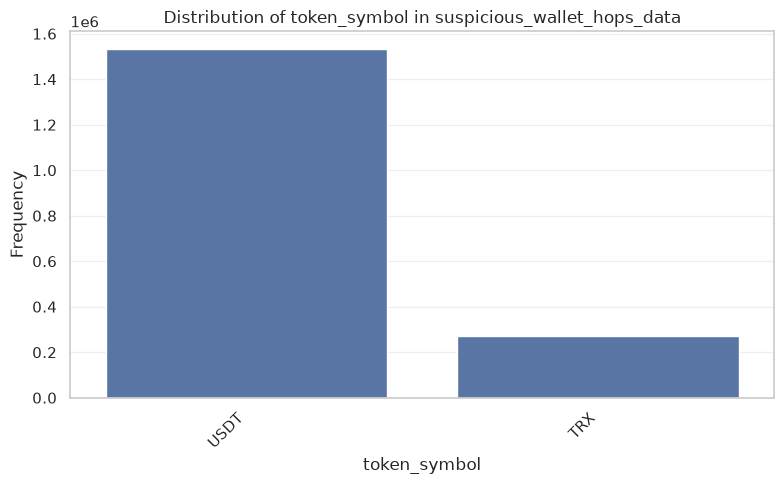

Plotting column: contract_address


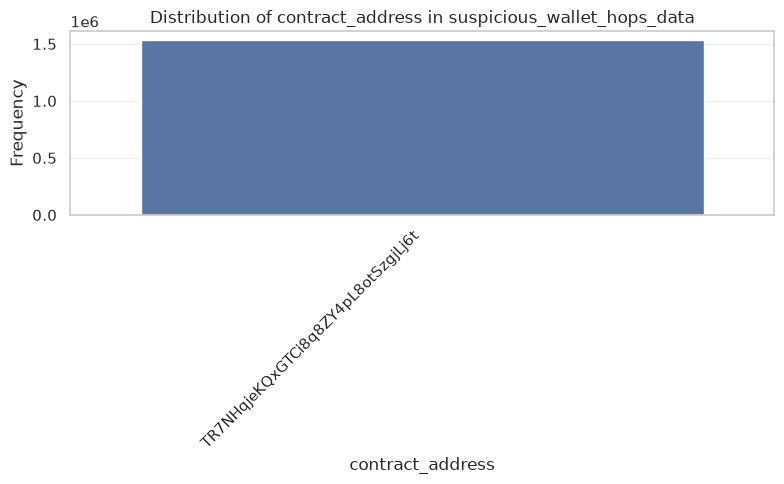

Skipping 'created_at': too many unique values (29599) for a clear plot.
====Plotting data suspicious_transactions_data named ind: 2====
Skipping 'wallet_address': too many unique values (8946) for a clear plot.
Skipping 'hex_address': too many unique values (8946) for a clear plot.
Skipping 'blacklisted_utc': too many unique values (7050) for a clear plot.
Skipping 'transaction_id': too many unique values (8946) for a clear plot.
Plotting column: source_name


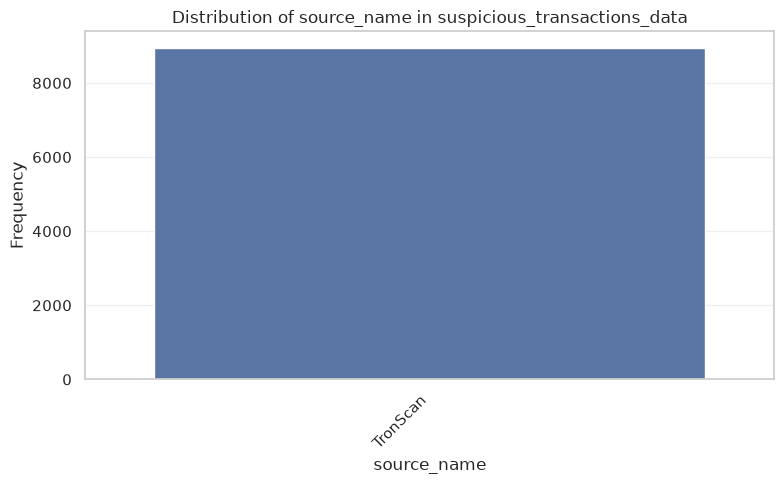

Plotting column: created_at


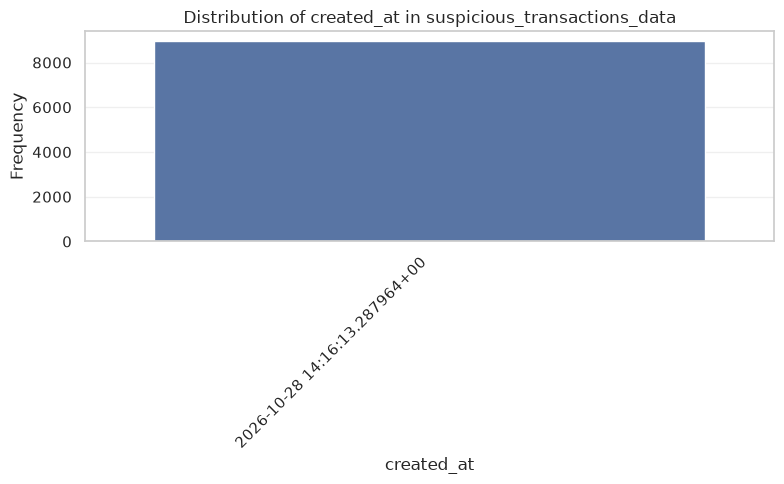

====Plotting data suspicious_blacklisted_data named ind: 3====
Skipping 'wallet_address': too many unique values (62166) for a clear plot.
Skipping 'seed_address': too many unique values (478) for a clear plot.
Skipping 'parent_address': too many unique values (10215) for a clear plot.
Skipping 'via_tx_hash': too many unique values (68834) for a clear plot.
Plotting column: direction


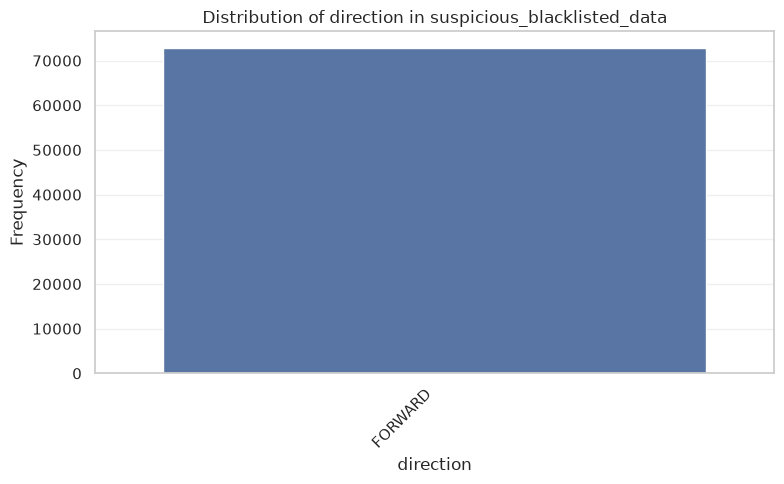

Skipping 'discovered_at': too many unique values (11153) for a clear plot.


In [49]:
univariate_countplot(cat_df_cols_dict,all_dfs_name,all_dfs)

#### 2. Numerical 

type: <class 'dict'>
====Plotting data suspicious_account_data named ind: 0====
====Plotting data suspicious_wallet_hops_data named ind: 1====
Skipping 'block_number': too many unique values (256838) for a clear plot.
Skipping 'amount': too many unique values (353397) for a clear plot.
Plotting column: fee_trx


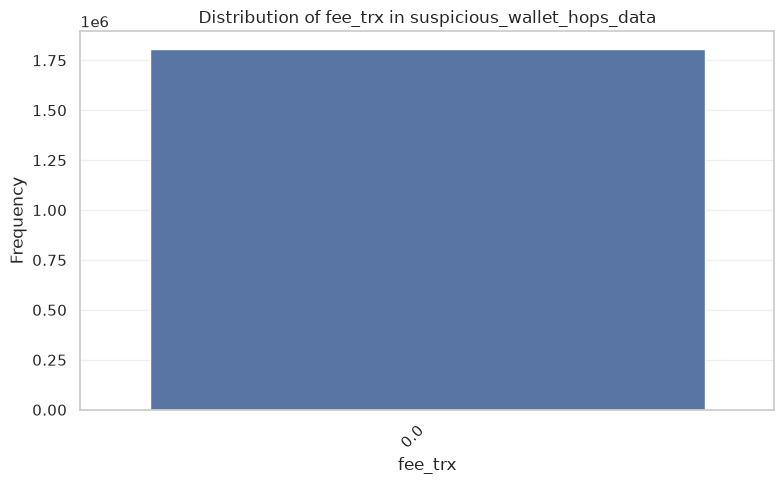

====Plotting data suspicious_transactions_data named ind: 2====
Skipping 'blacklisted_timestamp': too many unique values (7050) for a clear plot.
Plotting column: label


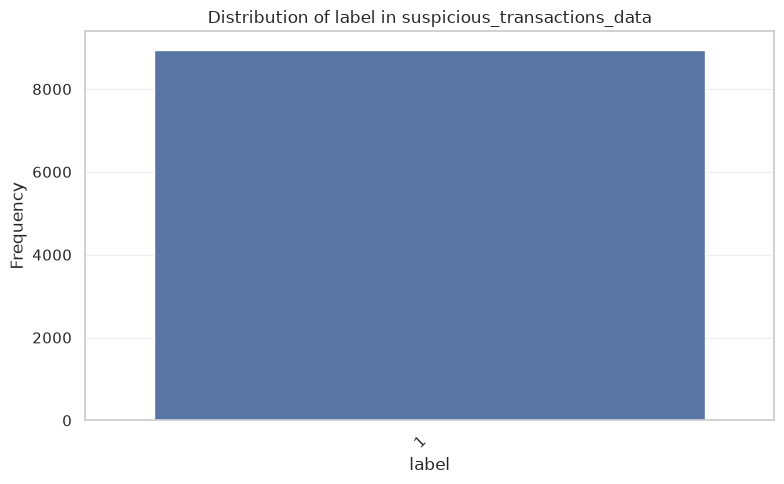

====Plotting data suspicious_blacklisted_data named ind: 3====
Skipping 'hop_id': too many unique values (72912) for a clear plot.
Plotting column: hop_level


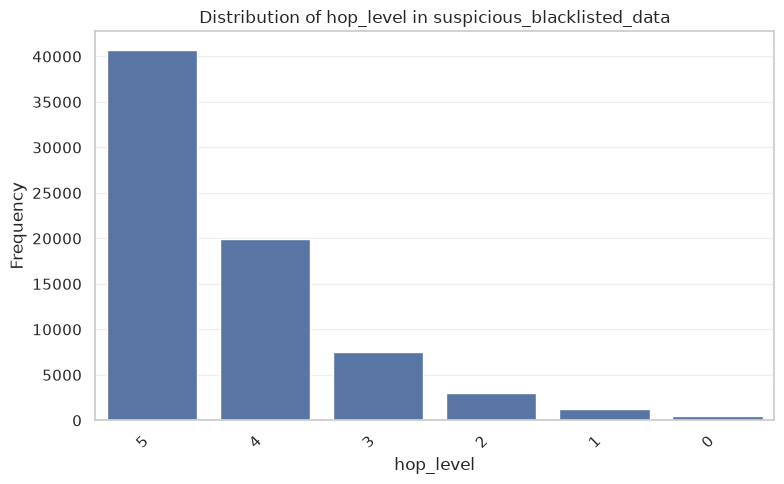

In [50]:
univariate_countplot(num_df_cols_dict, all_dfs_name, all_dfs)

### 4.2. Bivairate

## 5. Insights
- Drop columns:
  1. suspicious_account_data: hex_address.
  2. suspicpous_blacklisted_data: source_name, created_at, label.
  3. suspicious_transactions_data: contract_address,fee_trx
  4. suspicious_wallet_hops_data:"parent_address","via_tx_hash", ("direction")?
- New Columns needed:
  1. account_lifetime